## 1. Load the simulated localizations

Run notebook 00 first to create the matching HDF5/YAML pair in `data/simulated/digits_picasso_01/`. Positions and pick distances are in camera pixels

Install the base requirements and the pinned Addon in [requirements-autopicking.txt](../requirements-autopicking.txt) first.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle
from scipy.spatial import cKDTree
from sklearn.cluster import HDBSCAN
from picasso import io, lib, postprocess, render, localize
from picasso_addon import autopick

project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
data_file = project_dir / "data/simulated/digits_picasso_01/digits_locs.hdf5"
if not data_file.is_file() or not data_file.with_suffix(".yaml").is_file():
    raise FileNotFoundError("Run notebook 00 to generate digits_locs.hdf5 and digits_locs.yaml.")
locs, info = io.load_locs(str(data_file))
recording_name = data_file.stem.removesuffix("_locs")
width, height = (lib.get_from_metadata(info, key) for key in ["Width", "Height"])
pixel_size_nm = float(lib.get_from_metadata(info, "Pixelsize"))
print(f"Loaded {len(locs):,} detections from {recording_name}.")

Loaded 97,930 detections from digits.


## 2. Choose the common criteria

Each proposed center gets a circular crop. The **1.2-pixel radius** is a starting value for the simulated digit sizes, including localization spread. Increase it if a pattern is clipped; decrease it if a crop includes neighboring particles. Reselect these values if you change the simulation's pattern size or spacing.

Keep crops with **1,000–20,000 detections** and at least **85%** of nearby detections inside the circle. The nearby region has twice the pick radius. These checks reject weak, unusually bright or crowded candidates; they do not assess digit shape. Overlapping picks are rejected, and the whole nearby region must fit inside the analyzed bounds, including during preview.

In [2]:
pick_radius = 1.2  # Camera pixels; large enough to include a digit and its localization spread.
min_locs, max_locs = 1000, 20000  # Detections per circle, not docking sites or frames.
min_isolation = 0.85  # Inside radius / inside twice the radius; higher rejects more crowded picks.
preview_bounds = (22, 42, 22, 42)  # x_min, x_max, y_min, y_max; four particles in this run.
# Leave at least 2*pick_radius between each center and a preview edge.

def screen_centers(centers, tree, bounds):
    centers = np.unique(np.asarray(centers).reshape(-1, 2), axis=0)
    if not len(centers):
        return pd.DataFrame(columns=["x", "y", "n_locs", "isolation", "kept"])
    counts = tree.query_ball_point(centers, pick_radius, return_length=True)
    nearby = tree.query_ball_point(centers, 2*pick_radius, return_length=True)
    isolation = counts / np.maximum(nearby, 1)
    spacing = cKDTree(centers).query(centers, k=2)[0][:, 1]
    x0, x1, y0, y1 = bounds
    edge_distance = np.minimum.reduce([centers[:, 0]-x0, x1-centers[:, 0],
                                       centers[:, 1]-y0, y1-centers[:, 1]])
    kept = ((counts >= min_locs) & (counts <= max_locs) & (isolation >= min_isolation)
            & (spacing >= 2*pick_radius) & (edge_distance >= 2*pick_radius))
    return pd.DataFrame({"x": centers[:, 0], "y": centers[:, 1], "n_locs": counts,
                         "isolation": isolation, "kept": kept})

## 3. Manual / Picasso picking

Use this method when you want to choose a few particles yourself. Enter their approximate `(x, y)` centers from notebook 01; the examples below refer to the current simulated field.

With `expand_with_pick_similar=False`, only those circles are considered. Set it to `True` to let Picasso search for clouds with similar detection counts and spatial spread. This searches for similar size/brightness, not a matching digit, and can miss particles unlike your examples. `std_range` controls how broadly it accepts similar clouds.

In [3]:
# Approximate centers read from the rendered field; update after changing the simulation.
manual_centers = np.array([[26.3, 26.3], [36.7, 26.3],
                           [26.3, 36.7], [36.7, 36.7]])  # Each row is (x, y), in camera pixels.
manual_parameters = {
    "expand_with_pick_similar": False,  # False: just these centers; True: search for similar clouds.
    "std_range": 2.0,  # Expansion only: tolerance in standard deviations; higher is more permissive.
}

def manual_picasso(points, bounds):
    x0, x1, y0, y1 = bounds
    seeds = manual_centers[(manual_centers[:, 0] >= x0) & (manual_centers[:, 0] < x1)
                           & (manual_centers[:, 1] >= y0) & (manual_centers[:, 1] < y1)]
    if not manual_parameters["expand_with_pick_similar"] or not len(seeds):
        return seeds
    origin = np.array([x0, y0])
    local = pd.DataFrame(points-origin, columns=["x", "y"])
    metadata = [{"Width": x1-x0, "Height": y1-y0,
                 "Frames": lib.get_from_metadata(info, "Frames")}]
    centers = postprocess.pick_similar(local, metadata, (seeds-origin).tolist(),
        pick_shape="Circle", pick_size=2*pick_radius, std_range=manual_parameters["std_range"])
    return np.asarray(centers).reshape(-1, 2)+origin

## 4. HDBSCAN

Use HDBSCAN to propose centers from dense groups of positions. It labels sparse detections as noise and takes the mean position of each remaining cluster. The final circular crop can include detections labeled as noise; it does not save HDBSCAN's cluster memberships.

`min_cluster_size` controls the smallest group it considers a cluster. `min_samples` controls how many neighboring detections support a dense region. Larger values usually give fewer, more conservative proposals. A digit may split into several clusters if its sites look disconnected.

The full-field run uses overlapping tiles to keep the calculation manageable. This is a local approximation to HDBSCAN; changing the preview bounds or tile size can change its results.

In [4]:
hdbscan_parameters = {
    "min_cluster_size": 300,  # Minimum detections in a proposed cluster; separate from min_locs above.
    "min_samples": 20,  # Neighbor count for density estimation; higher treats more points as noise.
}

def hdbscan_centers(points, bounds):
    if len(points) < max(hdbscan_parameters.values()):
        return np.empty((0, 2))
    labels = HDBSCAN(**hdbscan_parameters).fit_predict(points)
    clustered = pd.DataFrame(points, columns=["x", "y"])
    clustered["cluster"] = labels
    return clustered.loc[labels >= 0].groupby("cluster")[["x", "y"]].mean().to_numpy()

## 5. Picasso Addon

Use the Addon for a quick image-based proposal: count localizations in image bins, find local maxima, then refine each center using the surrounding counts. This is the default for the separated simulated particles.

`oversampling` sets the number of bins per camera pixel. Higher values give a finer image but make it larger and may expose separate peaks within one digit. `min_n_locs` is the minimum count in the detection box, whose width is about twice `pick_radius`. Lower it to include dimmer clouds; higher values reject more weak peaks. The common circular checks still apply afterward.

In [5]:
addon_parameters = {
    "oversampling": 10,  # Bins per camera pixel along each axis; finer bins use more memory.
    "min_n_locs": 1000,  # Detections in the square detection box; not the final circular count.
}
if not hasattr(localize, "local_maxima"):
    localize.local_maxima = localize._local_maxima

def addon_centers(points, bounds):
    x0, x1, y0, y1 = bounds
    scale = addon_parameters["oversampling"]
    # Odd box width in rendered pixels, approximately one pick diameter.
    box = max(3, int(2*np.floor(pick_radius*scale-0.5)+1))
    _, image = render.render(pd.DataFrame(points, columns=["x", "y"]), info,
        disp_px_size=pixel_size_nm/scale, viewport=((y0, x0), (y1, x1)), blur_method=None)
    # Current Picasso's COM order requires dx before dy at this Addon boundary.
    y, x, dx, dy, _ = autopick.identifyspots_in_image(
        image.astype(float), addon_parameters["min_n_locs"], box)
    return np.column_stack(((x+dx+0.5)/scale+x0, (y+dy+0.5)/scale+y0))

methods = {"manual_picasso": manual_picasso, "hdbscan": hdbscan_centers,
           "picasso_addon": addon_centers}

## 6. Compare a preview

Each panel shows the same data with one method's proposed circles. **Green** passes all common checks; **orange** fails at least one. Look for one circle around each complete digit, without clipped sites or duplicate picks. The default preview contains four particles in the current simulation.

Adjust the relevant parameter cell, then rerun this preview. If needed, inspect `preview_results["hdbscan"]` (or another method name) for each proposal's count, isolation and keep flag. Counts alone do not establish correct particle separation or digit identity.

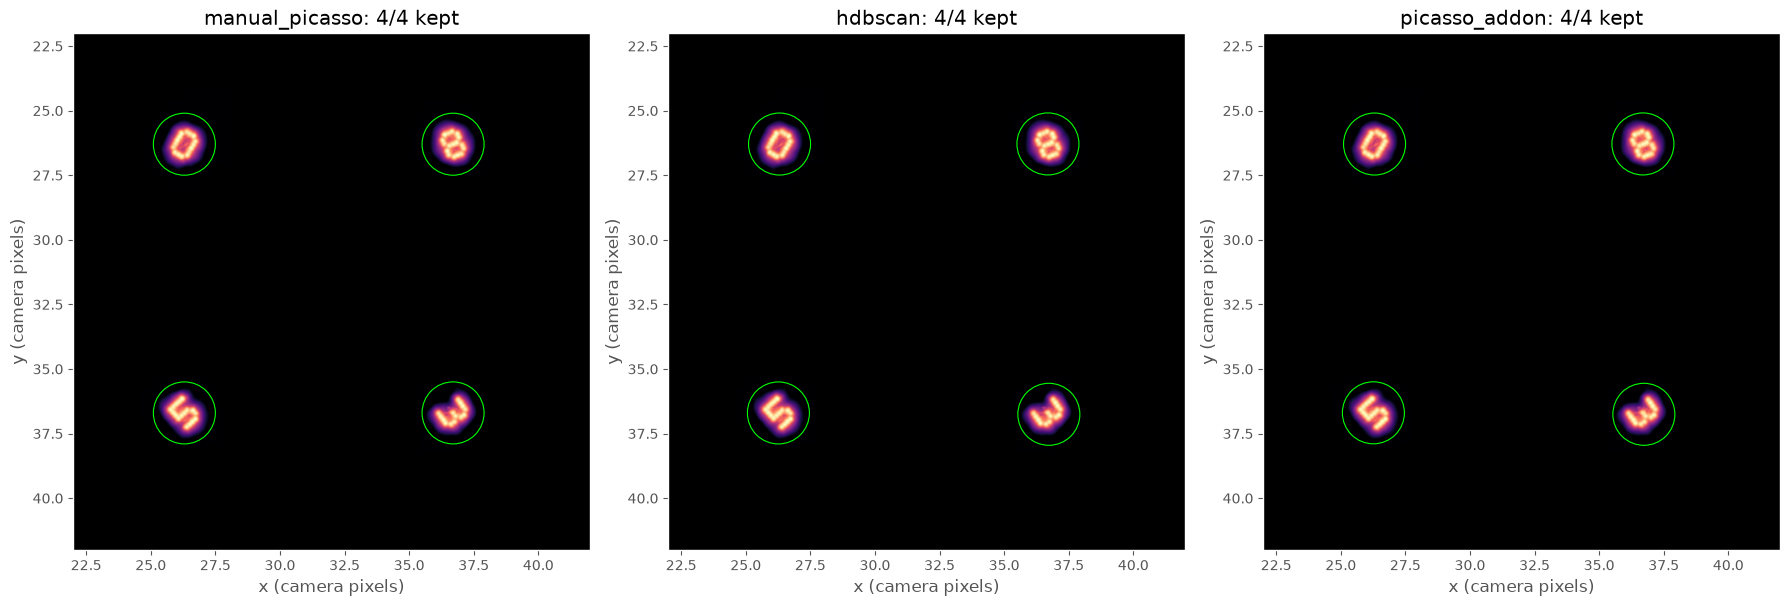

In [6]:
x0, x1, y0, y1 = preview_bounds
if not (0 <= x0 < x1 <= width and 0 <= y0 < y1 <= height):
    raise ValueError("Choose preview bounds within the field of view.")
preview_locs = locs.loc[(locs.x >= x0) & (locs.x < x1) & (locs.y >= y0) & (locs.y < y1)]
if preview_locs.empty:
    raise ValueError("No localizations in this preview. Choose different bounds.")
preview_xy = preview_locs[["x", "y"]].to_numpy(dtype=np.float64)
preview_tree = cKDTree(preview_xy)
_, image = render.render(preview_locs, info, disp_px_size=pixel_size_nm/32,
    viewport=((y0, x0), (y1, x1)), blur_method="gaussian")
cmap = plt.colormaps["magma"].with_extremes(bad="black")
vmax = np.percentile(image[image > 0], 99.8)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
preview_results = {}
for ax, (method, detector) in zip(axes, methods.items()):
    table = screen_centers(detector(preview_xy, preview_bounds), preview_tree, preview_bounds)
    preview_results[method] = table
    ax.imshow(image, origin="upper", extent=(x0, x1, y1, y0), cmap=cmap,
              norm=LogNorm(vmin=vmax/1000, vmax=vmax))
    for row in table.itertuples():
        ax.add_patch(Circle((row.x, row.y), pick_radius, fill=False,
                            color="lime" if row.kept else "orange", linewidth=0.8))
    ax.set(title=f"{method}: {int(table.kept.sum())}/{len(table)} kept",
           xlabel="x (camera pixels)", ylabel="y (camera pixels)")
    ax.grid(False)
fig.tight_layout()
plt.show()

## 7. Process the entire field

Choose `selected_method` after comparing the preview. **`picasso_addon`** is a useful starting point here; choose **`hdbscan`** for position-based clustering or **`manual_picasso`** to keep your chosen centers and optional similar-cloud search. The methods are alternatives; their picks are not combined.

With `run_full=True`, the selected method runs on the full field. Automatic methods use **16-pixel tiles** with a **3-pixel margin** around each tile. The margin includes particles near tile edges; each center is retained by one tile only. Keep `halo` at least twice `pick_radius`, and increase it if you enlarge the crops. Smaller tiles reduce work per tile but can change HDBSCAN results.

Common checks use all source detections. Overlapping circles are rejected. With manual expansion disabled, a full-field run still selects only your entered centers.

In [7]:
selected_method = "picasso_addon"  # Choose one: "manual_picasso", "hdbscan", or "picasso_addon".
run_full = True  # False: preview only, with no full-field processing or saved particle files.
run_id = "full_01"  # Output folder label; change it to keep a separate parameter trial.
tile_size = 16  # Camera pixels per tile; automatic methods only.
halo = 3  # Camera-pixel margin around each tile; keep >= 2*pick_radius.

if run_full:
    xy = locs[["x", "y"]].to_numpy(dtype=np.float64)
    source_tree = cKDTree(xy)
    detector = methods[selected_method]
    if selected_method == "manual_picasso":
        full_centers = detector(xy, (0, width, 0, height))
    else:
        found = []
        for core_y0 in np.arange(0, height, tile_size):
            for core_x0 in np.arange(0, width, tile_size):
                core_x1, core_y1 = min(core_x0+tile_size, width), min(core_y0+tile_size, height)
                bounds = (max(0, core_x0-halo), min(width, core_x1+halo),
                          max(0, core_y0-halo), min(height, core_y1+halo))
                x0, x1, y0, y1 = bounds
                ids = source_tree.query_ball_point(((x0+x1)/2, (y0+y1)/2),
                                                  np.hypot(x1-x0, y1-y0)/2)
                points = xy[ids]
                points = points[(points[:, 0] >= x0) & (points[:, 0] < x1)
                                & (points[:, 1] >= y0) & (points[:, 1] < y1)]
                centers = detector(points, bounds)
                owned = ((centers[:, 0] >= core_x0) & (centers[:, 0] < core_x1)
                         & (centers[:, 1] >= core_y0) & (centers[:, 1] < core_y1))
                found.append(centers[owned])
        full_centers = np.concatenate(found).reshape(-1, 2)
    screened = screen_centers(full_centers, source_tree, (0, width, 0, height))
    particles = screened.loc[screened.kept == True].sort_values(["y", "x"]).reset_index(drop=True)
    particles.insert(0, "group", np.arange(len(particles), dtype=np.uint32))
    groups = np.full(len(locs), -1, dtype=np.int32)
    if len(particles):
        kept_tree = cKDTree(particles[["x", "y"]].to_numpy())
        for start in range(0, len(locs), 500_000):
            distance, group = kept_tree.query(xy[start:start+500_000], distance_upper_bound=pick_radius)
            groups[start:start+len(distance)] = np.where(np.isfinite(distance), group, -1)
    picked = locs.iloc[np.flatnonzero(groups >= 0)].copy()
    picked["source_row"] = picked.index.to_numpy(dtype=np.uint64)
    picked["group"] = groups[groups >= 0].astype(np.uint32)
    print(f"Full field: {len(full_centers):,} proposed centers; {len(particles):,} kept particles; "
          f"{len(picked):,} selected detections.")

Full field: 30 proposed centers; 30 kept particles; 97,928 selected detections.


## 8. Save the selected particles

With `run_full=True`, save `picked_locs.hdf5`, matching YAML and `particles.csv` under `data/derived/digits/<run_id>/<selected_method>/`. Rerunning the same run/method overwrites those particle files; change `run_id` to keep a separate trial.

Original coordinates, frames and metadata are retained, adding numeric `group` and `source_row`. `particles.csv` links each group to its center and selection measurements. These group IDs describe this selection; they are not simulation particle IDs or digit classes.

In [8]:
if run_full:
    output_dir = project_dir / "data/derived" / recording_name / run_id / selected_method
    output_dir.mkdir(parents=True, exist_ok=True)
    detector_parameters = {"manual_picasso": {**manual_parameters, "centers": manual_centers.tolist()},
                           "hdbscan": hdbscan_parameters, "picasso_addon": addon_parameters}
    processing = {
        "Generated by": "02_find_particles", "Source": str(data_file.relative_to(project_dir)),
        "Method": selected_method, "Run": run_id, "Scope": "full recording",
        "Detector parameters": detector_parameters[selected_method],
        "Pick radius (camera pixels)": pick_radius, "Count range": [min_locs, max_locs],
        "Minimum isolation fraction": min_isolation, "Neighborhood radius factor": 2,
        "Non-overlap separation (camera pixels)": 2*pick_radius,
        "Tiled detection": selected_method != "manual_picasso",
        "Tile size (camera pixels)": tile_size, "Halo (camera pixels)": halo,
        "Particles": len(particles), "Selected detections": len(picked),
    }
    output_file = output_dir / "picked_locs.hdf5"
    io.save_locs(str(output_file), picked, info+[processing])
    io.save_info(str(output_file.with_suffix(".yaml")), info+[processing])
    particles.to_csv(output_dir / "particles.csv", index=False)
    print(f"Saved {output_dir.relative_to(project_dir)}")

Saved data/derived/digits/full_01/picasso_addon


## 9. Method, literature and parameter choices

**Method and literature:**

- **Manual / Picasso:** [Schnitzbauer et al. (2017)](https://doi.org/10.1038/nprot.2017.024) describes the Picasso software suite. This notebook uses circular picks and optionally calls `postprocess.pick_similar`, which compares localization counts and their spatial spread, as explained in the [Picasso picking manual](https://picassosr.readthedocs.io/en/latest/render.html#pick-similar-ctrl-shift-p). Similar size and brightness do not imply the same digit.
- **HDBSCAN:** [Campello, Moulavi and Sander (2013)](https://doi.org/10.1007/978-3-642-37456-2_14) introduces the hierarchical density-based clustering method. Here, [scikit-learn's implementation](https://scikit-learn.org/1.7/modules/generated/sklearn.cluster.HDBSCAN.html) groups localization positions; each cluster's mean proposes a center. Our tiled processing and later circular crops are notebook choices, not part of the original clustering algorithm.
- **Picasso Addon:** the authors' [autopicking guide](https://github.com/schwille-paint/picasso_addon/blob/master/docs/howto.rst) describes rendering localization counts, finding peaks, applying a box-count threshold and refining centers by center of mass. This notebook calls the Addon detector, then applies the common selection checks. It finds particle candidates rather than recognizing digit shapes.

**Parameter origins:** these are working values for the current simulation, checked with the preview; the references above do not prescribe these numerical thresholds. The **20 nm site spacing** and **130 nm camera pixels** are simulation assumptions from notebook 00. All pick distances below are in camera pixels.

| Parameters used here | Reason and effect |
|---|---|
| `pick_radius = 1.2` | A 156 nm radius at this calibration. The current 7 × 5 layouts span up to 80 × 120 nm before rotation, leaving room for localization spread. Increase if sites are clipped; an oversized crop can include neighbors. |
| `min_locs = 1000`, `max_locs = 20000` | Broad limits on detections per circle to reject weak or unusually bright crops. |
| `min_isolation = 0.85` | At least 85% of detections within twice the pick radius must lie inside the pick itself. Higher values reject more crowded crops. |
| `manual_centers`, `expand_with_pick_similar = False`, `std_range = 2.0` | Centers are examples chosen from the rendered field. Expansion is initially off; when enabled, the tolerance is two standard deviations of the seed picks' counts and spatial spread. A larger tolerance accepts a broader range. |
| `min_cluster_size = 300`, `min_samples = 20` | Require at least 300 detections per HDBSCAN cluster and use 20 samples for density estimation, including the point itself in scikit-learn. These control center proposals; `min_locs` separately screens the final circles. |
| `oversampling = 10`, `min_n_locs = 1000` | Addon bins are 13 nm wide at this calibration. A square detection box must contain at least 1,000 detections. Finer bins use more memory; a lower count threshold admits weaker peaks. |
| `tile_size = 16`, `halo = 3` | Computational settings for automatic full-field detection.  |

`preview_bounds` limits only the comparison image and preview detection. Choose `selected_method` after inspecting the circles; Addon is the current starting choice for these separated particles. Set `run_full=False` for preview-only tuning, or change `run_id` to save a separate full-field trial.

Particle counts and agreement between methods do not establish accuracy. Missing sites, localization spread and uneven blinking can shift centers or split a particle into several proposals.
